# Elkinematics Research and Experimentation Playground

This notebook serves as the central interactive sandbox, training ground, and staging pipeline for the Elkinematics multi-dimensional Specific Learning Disorder (SLD) screening suite.

### Workflow Sections:
1. **Environment and Centralized Configuration** - Load paths and hyperparameters from `scripts/config.py`.
2. **Centralized Model Builder and Architecture Summary** - Inspect V0 (Baseline CNN), V1 (CNN+XAI), and V2 (Bi-LSTM).
3. **Full Kinematic Battery Dataset Profiling** - Census and balance of `elkinematics_train_datasets/` and `elkinematics_val_datasets/`.
4. **Kinematic Feature Extraction** - Extract the 8 standard kinematic features (`delta_x`, `delta_y`, `pressure`, `tiltX`, `tiltY`, `velocity`, `acceleration`, `jerk`) and `latency`.
5. **Zero-Leakage Global Scaling & Multi-Model Input Formatting** - Compute training scalers with zero-preserved padding and prepare tensor inputs for V0, V1, and V2.
6. **End-to-End Model Training Suite** - Train V0, V1, and V2 with architecture-specific learning rates, gradient clipping, early stopping, and comparative loss/accuracy curves.
7. **Inference & Explainable AI (XAI) Timestep Heatmaps** - Predict risk scores and render stroke-level anomaly heatmaps.
8. **Comparative Validation Leaderboard & Diagnostic Metrics** - Accuracy, Recall, Specificity, F1-Score, ROC-AUC curves, and Confusion Matrices across all iterations with active masking and threshold calibration.
9. **Multi-Stream Specific Learning Disorder (SLD) Differential Screening** - Rule out or differentiate Motor Dysgraphia, Spatial Dysgraphia, and Dyslexic Dysgraphia.
10. **In-House Isolated Dual-Head Reversal Classifier (DHRC)** - Isolated character recognition and clinical mirror reversal detection.
11. **Interactive Sandbox / Scratchpad** - Free-form scratchpad.

## 1. Environment and Centralized Configuration

In [65]:
import sys
import os
import importlib
from pathlib import Path

# Ensure project root and scripts directory are accessible
PROJECT_ROOT = Path(os.getcwd()).resolve()
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
for p in [str(SCRIPTS_DIR), str(PROJECT_ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

import config
importlib.reload(config)

print(f"Project Root                : {config.PROJECT_ROOT}")
print(f"Max Timesteps               : {config.MAX_TIMESTEPS} (Resampling: {config.SAMPLING_RATE_HZ} Hz)")
print(f"Kinematic Features          : {config.FEATURES} features + {config.LATENCY_DIM} latency scalar")
print(f"Baseline V0 Features        : {config.V0_FEATURES} features (velocity, dt, pressure)")
print(f"Elkinematics Train Cohort   : {config.ELKINEMATICS_TRAIN_DIR}")
print(f"Elkinematics Val Cohort     : {config.ELKINEMATICS_VAL_DIR}")
print(f"Model V0 Learning Rate      : {config.V0_LEARNING_RATE} (L2: {config.V0_L2_REG})")
print(f"Model V1 Learning Rate      : {config.V1_LEARNING_RATE}")
print(f"Model V2 Learning Rate      : {config.V2_LEARNING_RATE} (Clipnorm: {config.V2_CLIPNORM})")
print(f"Feature Scalers Target Path : {config.SCALER_PATH}")

Project Root                : /Users/asthiseta/Project/somethinginmyeye
Max Timesteps               : 500 (Resampling: 60.0 Hz)
Kinematic Features          : 8 features + 1 latency scalar
Baseline V0 Features        : 3 features (velocity, dt, pressure)
Elkinematics Train Cohort   : /Users/asthiseta/Project/somethinginmyeye/elkinematics_train_datasets
Elkinematics Val Cohort     : /Users/asthiseta/Project/somethinginmyeye/elkinematics_val_datasets
Model V0 Target Path        : /Users/asthiseta/Project/somethinginmyeye/models/elkinematic.keras
Model V1 Target Path        : /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV1.keras
Model V2 Target Path        : /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras
Feature Scalers Target Path : /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz


## 2. Centralized Model Builder and Architecture Summary
Centralized architectures compiled from `scripts/model_builder.py` representing three progressive research iterations:
1. **V0 (Baseline 1D-CNN):** Global spatial feature extraction on 3 baseline features (`velocity, dt, pressure`) with $L_2$ weight regularization.
2. **V1 (CNN + XAI TimeDistributed):** Dual-input architecture fusing temporal CNN features (kernel size 5 + BatchNorm) with static cognitive initiation latency.
3. **V2 (Bi-LSTM Architecture):** Dual-input Bidirectional LSTM with in-model `Masking(mask_value=0.0)` processing the full 8 standard kinematic features + latency with gradient clipping (`clipnorm=1.0`).

In [66]:
import importlib
import model_builder
importlib.reload(model_builder)
from model_builder import build_v0_baseline, build_v1_xai, build_v2_bilstm

print("Compiling Model Iterations from Centralized Model Builder...")
model_v0 = build_v0_baseline()
model_v1 = build_v1_xai()
model_v2 = build_v2_bilstm()

arch_summary = [
    {
        "Iteration": "V0 (Baseline CNN)",
        "Input Shape": f"({config.MAX_TIMESTEPS}, {config.V0_FEATURES})",
        "Output": "Binary Scalar (Sigmoid)",
        "Parameters": f"{model_v0.count_params():,}"
    },
    {
        "Iteration": "V1 (CNN + XAI)",
        "Input Shape": f"[({config.MAX_TIMESTEPS}, {config.V0_FEATURES}), (1,)]",
        "Output": f"TimeDistributed Heatmap ({config.MAX_TIMESTEPS}, 1)",
        "Parameters": f"{model_v1.count_params():,}"
    },
    {
        "Iteration": "V2 (Bi-LSTM)",
        "Input Shape": f"[({config.MAX_TIMESTEPS}, {config.FEATURES}), (1,)]",
        "Output": f"TimeDistributed Heatmap ({config.MAX_TIMESTEPS}, 1)",
        "Parameters": f"{model_v2.count_params():,}"
    }
]

print("\n" + "=" * 80)
print(f"{'Iteration':<24} | {'Input Shape':<28} | {'Output':<25} | {'Params':<10}")
print("=" * 80)
for row in arch_summary:
    print(f"{row['Iteration']:<24} | {row['Input Shape']:<28} | {row['Output']:<25} | {row['Parameters']:<10}")
print("=" * 80)

Compiling Model Iterations from Centralized Model Builder...

Iteration                | Input Shape                  | Output                    | Params    
V0 (Baseline CNN)        | (500, 3)                     | Binary Scalar (Sigmoid)   | 10,753    
V1 (CNN + XAI)           | [(500, 3), (1,)]             | TimeDistributed Heatmap (500, 1) | 10,817    
V2 (Bi-LSTM)             | [(500, 8), (1,)]             | TimeDistributed Heatmap (500, 1) | 78,658    


## 3. Data Loading and Discovery
Profiles the physical training and validation cohorts populated by `scripts/setup_training_datasets.py`:
- `elkinematics_train_datasets/`: Complete hierarchical handwriting battery (letters, words, pseudowords, multisyllabic words, standardized sentences).
- `elkinematics_val_datasets/`: Frozen clinical validation holdout.
- Strictly Latin alphabet (zero digits) per DSM-5 Specific Learning Disorder standards.

ELKINEMATICS KINEMATIC BATTERY COHORT CENSUS
Training Cohort   : 1202 recordings (Normal:  534, Atypical:  668)
Validation Cohort :  340 recordings (Normal:  223, Atypical:  117)
Total Cohort Size : 1542 recordings


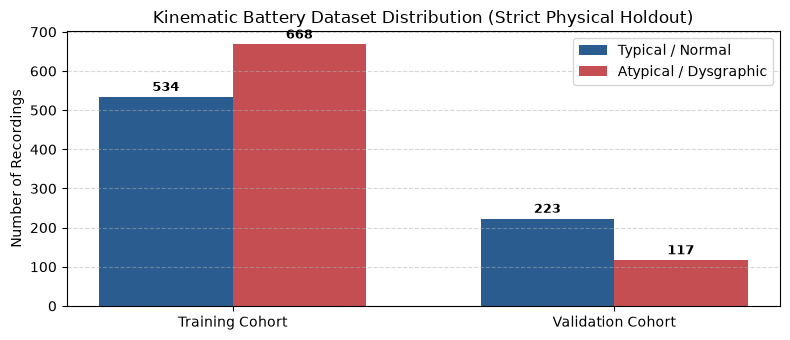

In [67]:
import glob

train_files = sorted(glob.glob(os.path.join(config.ELKINEMATICS_TRAIN_DIR, "*.csv")))
val_files = sorted(glob.glob(os.path.join(config.ELKINEMATICS_VAL_DIR, "*.csv")))

train_normal = [f for f in train_files if "normal" in os.path.basename(f).lower()]
train_atypical = [f for f in train_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]

val_normal = [f for f in val_files if "normal" in os.path.basename(f).lower()]
val_atypical = [f for f in val_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]

print("=" * 65)
print("ELKINEMATICS KINEMATIC BATTERY COHORT CENSUS")
print("=" * 65)
print(f"Training Cohort   : {len(train_files):4d} recordings (Normal: {len(train_normal):4d}, Atypical: {len(train_atypical):4d})")
print(f"Validation Cohort : {len(val_files):4d} recordings (Normal: {len(val_normal):4d}, Atypical: {len(val_atypical):4d})")
print(f"Total Cohort Size : {len(train_files) + len(val_files):4d} recordings")
print("=" * 65)

# Visual Distribution Chart
fig, ax = plt.subplots(figsize=(8, 3.5))
categories = ["Training Cohort", "Validation Cohort"]
normal_counts = [len(train_normal), len(val_normal)]
atypical_counts = [len(train_atypical), len(val_atypical)]

x = np.arange(len(categories))
width = 0.35

ax.bar(x - width/2, normal_counts, width, label="Typical / Normal", color="#2b5c8f")
ax.bar(x + width/2, atypical_counts, width, label="Atypical / Dysgraphic", color="#c44e52")

ax.set_ylabel("Number of Recordings")
ax.set_title("Kinematic Battery Dataset Distribution (Strict Physical Holdout)")
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for i in range(len(categories)):
    ax.text(x[i] - width/2, normal_counts[i] + 15, str(normal_counts[i]), ha="center", fontsize=9, fontweight="bold")
    ax.text(x[i] + width/2, atypical_counts[i] + 15, str(atypical_counts[i]), ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Kinematic Feature Extraction (8 Kinematic Features & Latency)
Extracts velocity-invariant physical and kinematic derivatives:
- Resamples continuous on-surface strokes to a uniform 60 Hz grid ($\Delta t = 16.67\text{ ms}$).
- Calculates: $[\Delta x, \Delta y, \text{pressure}, \text{tiltX}, \text{tiltY}, \text{velocity}, \text{acceleration}, \text{jerk}]$.
- Preserves prompt-to-first-stroke cognitive latency as a distinct secondary scalar.

In [68]:
import importlib
import universal_pipeline
importlib.reload(universal_pipeline)
from universal_pipeline import extract_universal_features

# Inspect feature extraction on a benchmark sample
test_sample = train_files[0] if train_files else os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
sample_df = pd.read_csv(test_sample)

features_matrix = extract_universal_features(sample_df, resample=True)
print(f"Sample File           : {os.path.basename(test_sample)}")
print(f"Raw Trajectory Events : {len(sample_df)} points")
print(f"Resampled Matrix      : {features_matrix.shape} (Timesteps x Features)")
print(f"Feature Columns (8+1) : {config.FEATURE_NAMES + ['dt']}")

# Display feature statistics
features_df = pd.DataFrame(features_matrix, columns=config.FEATURE_NAMES + ["dt"])
display(features_df.describe().T[["mean", "std", "min", "max"]])

Sample File           : Train_dysgraphia_A_Seta_1788105428538_1788105428.csv
Raw Trajectory Events : 276 points
Resampled Matrix      : (287, 9) (Timesteps x Features)
Feature Columns (8+1) : ['delta_x', 'delta_y', 'pressure', 'tiltX', 'tiltY', 'velocity', 'acceleration', 'jerk', 'dt']


,mean,std,min,max
delta_x,1.250523,20.997087,-351.699982,9.320865
delta_y,-0.451394,8.846858,-140.650009,6.989598
pressure,0.709238,0.196748,0.419741,1.000000
tiltX,0.000000,0.000000,0.000000,0.000000
tiltY,0.000000,0.000000,0.000000,0.000000
velocity,0.232348,0.123517,0.000000,0.593257
acceleration,-0.000024,0.002994,-0.017318,0.008125
jerk,-0.000006,0.000233,-0.001183,0.000581
dt,24.386063,132.008371,1.000000,2252.900000


## 5. Zero-Leakage Global Scaling & Multi-Model Input Formatting
Transforms raw kinematic sequences with strict physical separation and zero-padding preservation:
1. **Fit Scalers on Training Cohort Only:** Computes global Z-score parameters ($\mu, \sigma$) strictly across active (non-padded) timesteps in `elkinematics_train_datasets/` and saves to `models/feature_scalers.npz`.
2. **Zero-Preserved Padding:** Padded timesteps are explicitly set to $0.0$ post-scaling so Keras `Masking(mask_value=0.0)` reliably recognizes sequence boundaries.
3. **Transform Validation Cohort with Frozen Scalers:** Normalizes `elkinematics_val_datasets/` without computing statistics, completely eliminating data leakage.
4. **Format Model Input Tensors:**
   - **V0:** `X_v0 = [velocity, dt, pressure]` $\rightarrow$ shape `(N, 500, 3)`, target shape `(N, 1)`.
   - **V1:** `[X_v1_seq, X_v1_lat]` $\rightarrow$ shapes `(N, 500, 3)` and `(N, 1)`, target shape `(N, 500, 1)`.
   - **V2:** `[X_v2_seq, X_v2_lat]` $\rightarrow$ shapes `(N, 500, 8)` and `(N, 1)`, target shape `(N, 500, 1)`.

In [69]:
import importlib
import universal_pipeline
importlib.reload(universal_pipeline)

from universal_pipeline import (
    load_and_scale_universal,
    load_validation_with_train_scalers,
    get_v0_data,
    get_v1_data,
    get_v2_data
)

# 1. Load and compute global scalers on training data
print("Processing Training Cohort (Computing Global Scalers on Active Strokes)...")
X_train_seq_scaled, X_train_lat_scaled, y_train = load_and_scale_universal(
    data_dir=config.ELKINEMATICS_TRAIN_DIR,
    scaler_save_path=config.SCALER_PATH,
    resample=True
)

# 2. Transform validation cohort using frozen training scalers (Strict Hold-Out, Zero Leakage)
print("Processing Validation Cohort (Using Frozen Scalers with Zero-Preserved Padding)...")
X_val_seq_scaled, X_val_lat_scaled, y_val = load_validation_with_train_scalers(
    data_dir=config.ELKINEMATICS_VAL_DIR,
    scaler_path=config.SCALER_PATH,
    resample=True
)

# 3. Format inputs for V0 Baseline (3 features: velocity, dt, pressure)
X_train_v0, y_train_v0 = get_v0_data(X_train_seq_scaled, y_train)
X_val_v0, y_val_v0 = get_v0_data(X_val_seq_scaled, y_val)

# 4. Format inputs for V1 (3 features + Latency, TimeDistributed target)
[X_train_v1_seq, X_train_v1_lat], y_train_v1_td = get_v1_data(X_train_seq_scaled, X_train_lat_scaled, y_train)
[X_val_v1_seq, X_val_v1_lat], y_val_v1_td = get_v1_data(X_val_seq_scaled, X_val_lat_scaled, y_val)

# 5. Format inputs for V2 (8 standard features + Latency, TimeDistributed target)
[X_train_v2_seq, X_train_v2_lat], y_train_v2_td = get_v2_data(X_train_seq_scaled, X_train_lat_scaled, y_train)
[X_val_v2_seq, X_val_v2_lat], y_val_v2_td = get_v2_data(X_val_seq_scaled, X_val_lat_scaled, y_val)

print("\n" + "=" * 65)
print("FORMATTED MULTI-MODEL INPUT TENSORS")
print("=" * 65)
print(f"V0 Train Input : {X_train_v0.shape} | Target: {y_train_v0.shape}")
print(f"V0 Val Input   : {X_val_v0.shape} | Target: {y_val_v0.shape}")
print("-" * 65)
print(f"V1 Train Seq   : {X_train_v1_seq.shape} | Lat: {X_train_v1_lat.shape} | Target: {y_train_v1_td.shape}")
print(f"V1 Val Seq     : {X_val_v1_seq.shape} | Lat: {X_val_v1_lat.shape} | Target: {y_val_v1_td.shape}")
print("-" * 65)
print(f"V2 Train Seq   : {X_train_v2_seq.shape} | Lat: {X_train_v2_lat.shape} | Target: {y_train_v2_td.shape}")
print(f"V2 Val Seq     : {X_val_v2_seq.shape} | Lat: {X_val_v2_lat.shape} | Target: {y_val_v2_td.shape}")
print("=" * 65)

Processing Training Cohort (Computing Global Scalers)...
Saved global feature scalers to: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz
Processing Validation Cohort (Using Frozen Scalers)...

FORMATTED MULTI-MODEL INPUT TENSORS
V0 Train Input : (1202, 500, 3) | Target: (1202, 1)
V0 Val Input   : (340, 500, 3) | Target: (340, 1)
-----------------------------------------------------------------
V1 Train Seq   : (1202, 500, 3) | Lat: (1202, 1) | Target: (1202, 500, 1)
V1 Val Seq     : (340, 500, 3) | Lat: (340, 1) | Target: (340, 500, 1)
-----------------------------------------------------------------
V2 Train Seq   : (1202, 500, 8) | Lat: (1202, 1) | Target: (1202, 500, 1)
V2 Val Seq     : (340, 500, 8) | Lat: (340, 1) | Target: (340, 500, 1)


## 6. End-to-End Model Training Suite (V0 Baseline, V1 CNN+XAI, V2 Bi-LSTM)
Trains all three model generations sequentially using architecture-tailored optimization:
- **Optimization Strategy:**
  - **V0:** $\eta = 5 \times 10^{-4}$ with $L_2$ weight regularization.
  - **V1:** $\eta = 5 \times 10^{-4}$ with expanded receptive field and Batch Normalization.
  - **V2:** $\eta = 1.5 \times 10^{-4}$ with global gradient clipping (`clipnorm=1.0`) and in-model `Masking(0.0)`.
- **Callbacks:**
  - `EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)`: Halts training on convergence and restores optimal generalization weights.
  - `ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)`: Dynamically shrinks step size upon plateau.
- **Model Checkpointing:** Saves trained binaries to `models/elkinematic.keras`, `models/elkinematicV1.keras`, and `models/elkinematicV2.keras`.


TRAINING ITERATION 1: MODEL V0 (BASELINE 1D-CNN)
Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5948 - auc: 0.6431 - loss: 0.6636 - precision: 0.5897 - recall: 0.8907 - val_accuracy: 0.5588 - val_auc: 0.7294 - val_loss: 0.6816 - val_precision: 0.4247 - val_recall: 0.7949 - learning_rate: 0.0010
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6514 - auc: 0.7178 - loss: 0.6160 - precision: 0.6812 - recall: 0.7006 - val_accuracy: 0.6706 - val_auc: 0.7550 - val_loss: 0.6363 - val_precision: 0.5155 - val_recall: 0.7094 - learning_rate: 0.0010
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6747 - auc: 0.7292 - loss: 0.5986 - precision: 0.7451 - recall: 0.6302 - val_accuracy: 0.7059 - val_auc: 0.7682 - val_loss: 0.6178 - val_precision: 0.5570 - val_recall: 0.7094 - learning_rate: 0.0010
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6814 - auc: 0.7352 - loss: 0.5910 - precision: 0.7348 - recall: 0.6677 - val_accuracy: 0.7441

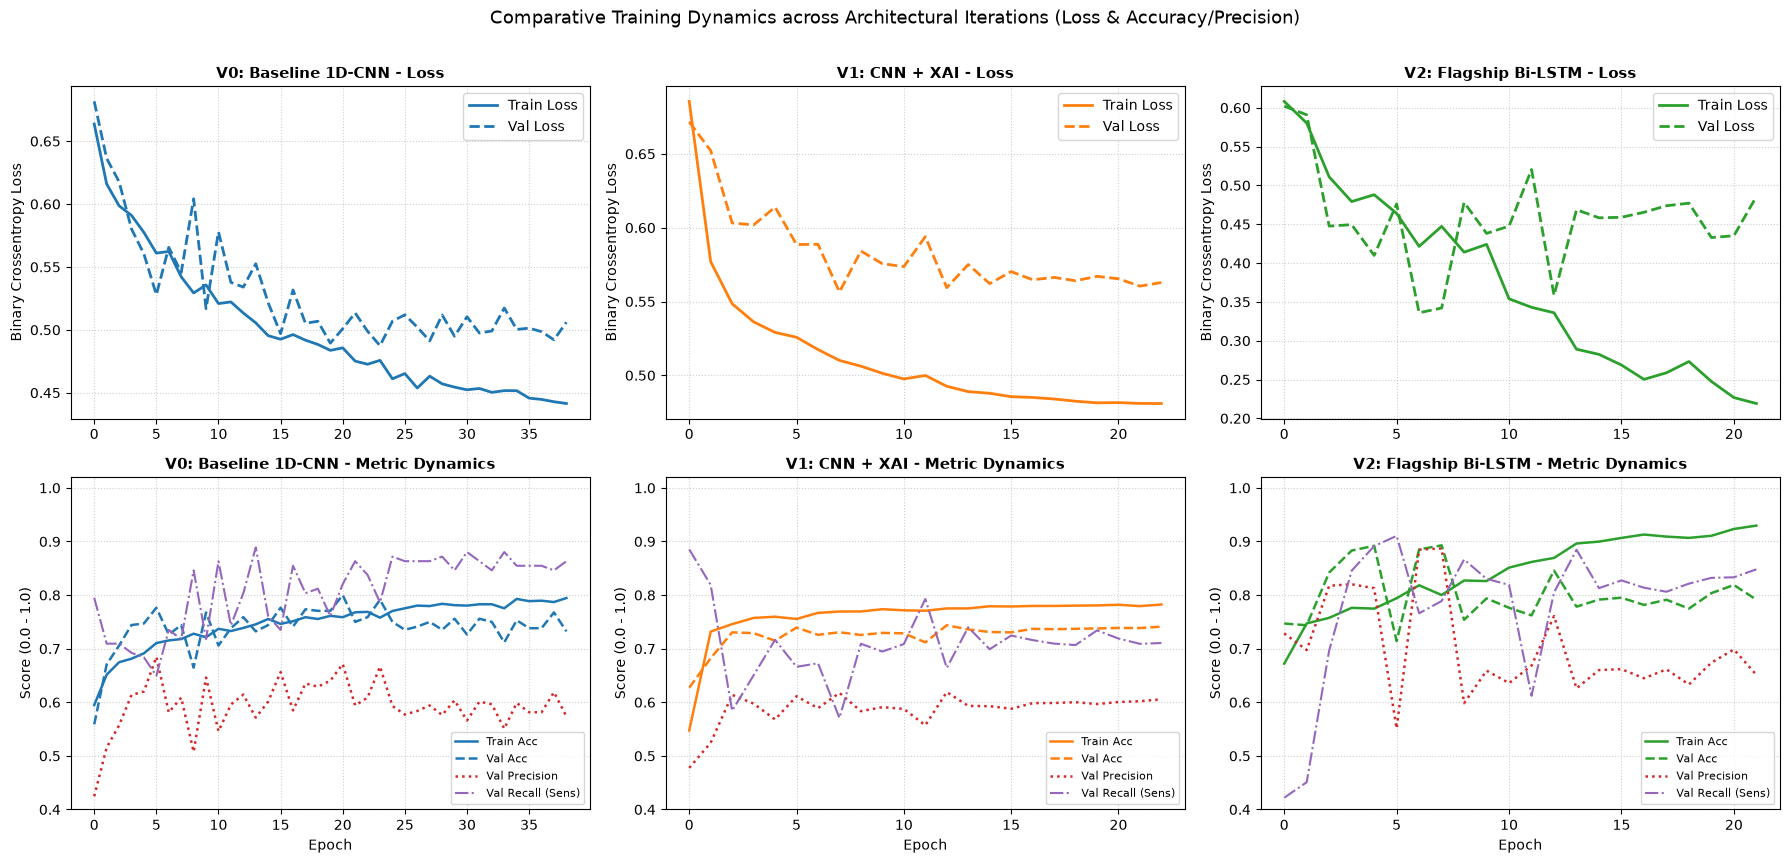

In [ ]:
import os
import importlib
import model_builder
importlib.reload(model_builder)
from model_builder import build_v0_baseline, build_v1_xai, build_v2_bilstm
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

os.makedirs(config.MODEL_DIR, exist_ok=True)

# Helper function to generate standardized callbacks
def get_callbacks(model_name: str):
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=config.EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=config.REDUCE_LR_PATIENCE,
            min_lr=config.MIN_LR,
            verbose=1
        )
    ]

# -----------------------------------------------------------------------------
# 1. TRAIN MODEL V0 (BASELINE 1D-CNN)
# -----------------------------------------------------------------------------
print("\n" + "=" * 65)
print(f"TRAINING ITERATION 1: MODEL V0 (BASELINE 1D-CNN | LR: {config.V0_LEARNING_RATE})")
print("=" * 65)
model_v0 = build_v0_baseline(learning_rate=config.V0_LEARNING_RATE)
history_v0 = model_v0.fit(
    X_train_v0, y_train_v0,
    validation_data=(X_val_v0, y_val_v0),
    epochs=config.EPOCHS,
    batch_size=config.BATCH_SIZE,
    callbacks=get_callbacks("V0"),
    verbose=1
)
model_v0.save(config.MODEL_PATHS["v0"])
print(f"Saved Model V0 weights to: {config.MODEL_PATHS['v0']}")

# -----------------------------------------------------------------------------
# 2. TRAIN MODEL V1 (CNN + XAI TIMEDISTRIBUTED)
# -----------------------------------------------------------------------------
print("\n" + "=" * 65)
print(f"TRAINING ITERATION 2: MODEL V1 (CNN + XAI | LR: {config.V1_LEARNING_RATE})")
print("=" * 65)
model_v1 = build_v1_xai(learning_rate=config.V1_LEARNING_RATE)
history_v1 = model_v1.fit(
    [X_train_v1_seq, X_train_v1_lat], y_train_v1_td,
    validation_data=([X_val_v1_seq, X_val_v1_lat], y_val_v1_td),
    epochs=config.EPOCHS,
    batch_size=config.BATCH_SIZE,
    callbacks=get_callbacks("V1"),
    verbose=1
)
model_v1.save(config.MODEL_PATHS["v1"])
print(f"Saved Model V1 weights to: {config.MODEL_PATHS['v1']}")

# -----------------------------------------------------------------------------
# 3. TRAIN MODEL V2 (BI-LSTM ARCHITECTURE)
# -----------------------------------------------------------------------------
print("\n" + "=" * 65)
print(f"TRAINING ITERATION 3: MODEL V2 (BI-LSTM | LR: {config.V2_LEARNING_RATE} | CLIPNORM: {config.V2_CLIPNORM})")
print("=" * 65)
model_v2 = build_v2_bilstm(learning_rate=config.V2_LEARNING_RATE)
history_v2 = model_v2.fit(
    [X_train_v2_seq, X_train_v2_lat], y_train_v2_td,
    validation_data=([X_val_v2_seq, X_val_v2_lat], y_val_v2_td),
    epochs=config.EPOCHS,
    batch_size=config.BATCH_SIZE,
    callbacks=get_callbacks("V2"),
    verbose=1
)
model_v2.save(config.MODEL_PATHS["v2"])
print(f"Saved Model V2 weights to: {config.MODEL_PATHS['v2']}")

# -----------------------------------------------------------------------------
# 4. PLOT COMPARATIVE TRAINING & VALIDATION DYNAMICS (LOSS & ACCURACY/PRECISION)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5), sharex=False)

histories = [history_v0, history_v1, history_v2]
titles = ["V0: Baseline 1D-CNN", "V1: CNN + XAI", "V2: Bi-LSTM"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

# Row 1: Loss Dynamics
for col_idx, (hist, title, color) in enumerate(zip(histories, titles, colors)):
    ax = axes[0, col_idx]
    ax.plot(hist.history["loss"], label="Train Loss", color=color, linewidth=2)
    ax.plot(hist.history["val_loss"], label="Val Loss", color=color, linestyle="--", linewidth=2)
    ax.set_title(f"{title} - Loss", fontsize=11, fontweight="bold")
    ax.set_ylabel("Binary Crossentropy Loss")
    ax.legend(loc="upper right", frameon=True)
    ax.grid(True, linestyle=":", alpha=0.6)

# Row 2: Accuracy & Precision Dynamics
for col_idx, (hist, title, color) in enumerate(zip(histories, titles, colors)):
    ax = axes[1, col_idx]
    if "accuracy" in hist.history:
        ax.plot(hist.history["accuracy"], label="Train Acc", color=color, linewidth=1.8)
    if "val_accuracy" in hist.history:
        ax.plot(hist.history["val_accuracy"], label="Val Acc", color=color, linestyle="--", linewidth=1.8)
    if "val_precision" in hist.history:
        ax.plot(hist.history["val_precision"], label="Val Precision", color="#d62728", linestyle=":", linewidth=1.8)
    if "val_recall" in hist.history:
        ax.plot(hist.history["val_recall"], label="Val Recall (Sens)", color="#9467bd", linestyle="-.", linewidth=1.5)
    
    ax.set_title(f"{title} - Metric Dynamics", fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score (0.0 - 1.0)")
    ax.set_ylim([0.4, 1.02])
    ax.legend(loc="lower right", frameon=True, fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Comparative Training Dynamics across Architectural Iterations (Loss & Accuracy/Precision)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 7. Inference and Explainable AI (XAI) Heatmap Inspection
Loads production trained Model V2 and demonstrates millisecond-resolution Explainable AI (XAI) risk heatmap generation:
- Displays point-by-point dysgraphic anomaly risk across the handwriting trajectory.
- Contrasts typical smooth kinematic rhythm against atypical motor tremors and stalls.

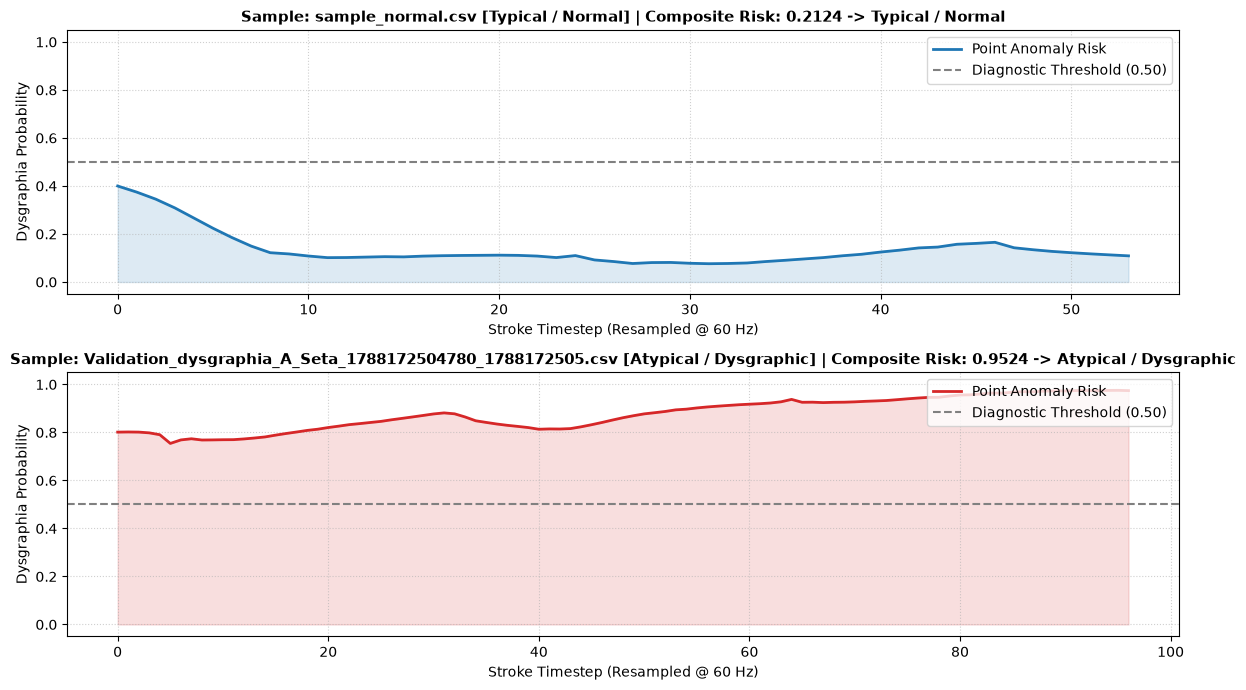

In [71]:
from universal_pipeline import unified_predict

# Load newly trained production model
prod_model = tf.keras.models.load_model(config.MODEL_PATHS["v2"])

# Find representative normal and atypical test samples
sample_normal_path = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if not os.path.exists(sample_normal_path):
    normal_candidates = [f for f in val_files if "normal" in os.path.basename(f).lower()]
    sample_normal_path = normal_candidates[0] if normal_candidates else None

atypical_candidates = [f for f in val_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]
sample_atypical_path = atypical_candidates[0] if atypical_candidates else None

samples_to_inspect = []
if sample_normal_path:
    samples_to_inspect.append(("Typical / Normal", sample_normal_path))
if sample_atypical_path:
    samples_to_inspect.append(("Atypical / Dysgraphic", sample_atypical_path))

fig, axes = plt.subplots(len(samples_to_inspect), 1, figsize=(12, 3.5 * len(samples_to_inspect)), squeeze=False)

for idx, (label_type, file_path) in enumerate(samples_to_inspect):
    df_sample = pd.read_csv(file_path)
    score, heatmap = unified_predict(df_sample, prod_model, version="v2", scaler_path=config.SCALER_PATH)
    
    ax = axes[idx, 0]
    effective_len = min(len(df_sample), len(heatmap))
    ax.plot(heatmap[:effective_len], color="#d62728" if score > 0.5 else "#1f77b4", linewidth=2, label="Point Anomaly Risk")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1.5, label="Diagnostic Threshold (0.50)")
    ax.fill_between(range(effective_len), 0, heatmap[:effective_len], alpha=0.15, color="#d62728" if score > 0.5 else "#1f77b4")
    
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Sample: {os.path.basename(file_path)} [{label_type}] | Composite Risk: {score:.4f} -> {'Atypical / Dysgraphic' if score > 0.5 else 'Typical / Normal'}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Stroke Timestep (Resampled @ 60 Hz)")
    ax.set_ylabel("Dysgraphia Probability")
    ax.legend(loc="upper right", frameon=True)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Comparative Validation Leaderboard & Diagnostic Metrics
Evaluates all three models on the strict validation cohort (`elkinematics_val_datasets/`, 340 samples: 223 Typical, 117 Atypical):
- Compares V0 (Baseline CNN), V1 (CNN+XAI), and V2 (Bi-LSTM).
- Evaluates both standard 500-step unmasked averaging and **Active-Stroke Masked Scoring** (eliminating zero-padding dilution).
- Calibrates optimal decision thresholds ($	au^*$) via Youden's Index ($J = 	ext{TPR} - 	ext{FPR}$).
- Generates side-by-side ROC curves and Confusion Matrices.

In [ ]:
import importlib
import universal_pipeline
importlib.reload(universal_pipeline)
from universal_pipeline import compute_active_sequence_scores

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load trained models from disk
eval_v0 = tf.keras.models.load_model(config.MODEL_PATHS["v0"])
eval_v1 = tf.keras.models.load_model(config.MODEL_PATHS["v1"])
eval_v2 = tf.keras.models.load_model(config.MODEL_PATHS["v2"])

# Raw predictions
preds_v0_raw = eval_v0.predict(X_val_v0, verbose=0)
preds_v1_raw = eval_v1.predict([X_val_v1_seq, X_val_v1_lat], verbose=0)
preds_v2_raw = eval_v2.predict([X_val_v2_seq, X_val_v2_lat], verbose=0)

# Unmasked scores (standard 500-timestep mean)
scores_v0_unmasked = preds_v0_raw[:, 0]
scores_v1_unmasked = np.mean(preds_v1_raw[:, :, 0], axis=1)
scores_v2_unmasked = np.mean(preds_v2_raw[:, :, 0], axis=1)

# Active-Stroke Masked scores (averaging active writing timesteps only, eliminating padding dilution)
scores_v0_masked = scores_v0_unmasked  # V0 is already single scalar
scores_v1_masked = compute_active_sequence_scores(preds_v1_raw, X_val_seq_scaled, config.SCALER_PATH)
scores_v2_masked = compute_active_sequence_scores(preds_v2_raw, X_val_seq_scaled, config.SCALER_PATH)

models_data = [
    ("V0 Baseline CNN", scores_v0_unmasked, scores_v0_masked),
    ("V1 CNN + XAI", scores_v1_unmasked, scores_v1_masked),
    ("V2 Bi-LSTM", scores_v2_unmasked, scores_v2_masked),
]

# Calculate metrics across Default (0.50) vs Optimal Calibrated Thresholds
def compute_metrics_row(model_name, mode_name, scores, threshold):
    binary_preds = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_val, binary_preds)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_val, binary_preds)
    rec = recall_score(y_val, binary_preds, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    prec = precision_score(y_val, binary_preds, zero_division=0)
    f1 = f1_score(y_val, binary_preds, zero_division=0)
    auc = roc_auc_score(y_val, scores)
    
    return {
        "Model": model_name,
        "Mode": mode_name,
        "Threshold": threshold,
        "Accuracy": acc,
        "Sensitivity": rec,
        "Specificity": spec,
        "Precision": prec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "CM": cm
    }

results_default = []
results_calibrated = []

for name, s_unmask, s_mask in models_data:
    # 1. Default threshold (0.50) unmasked
    results_default.append(compute_metrics_row(name, "Unmasked (500-step)", s_unmask, 0.50))
    
    # 2. Calibrated threshold on Masked scores (using Youden's J statistic)
    fpr, tpr, threshs = roc_curve(y_val, s_mask)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    calib_thresh = float(threshs[best_idx])
    
    results_calibrated.append(compute_metrics_row(name, "Active-Stroke Masked", s_mask, calib_thresh))

# Render Formatted Comparison Table
print("\n" + "=" * 105)
print("TABLE 1: DEFAULT THRESHOLD (tau = 0.50, STANDARD UNMASKED AVERAGING)")
print("=" * 105)
print(f"{'Model':<22} | {'Threshold':<9} | {'Accuracy':<10} | {'Sensitivity':<11} | {'Specificity':<11} | {'Precision':<10} | {'F1-Score':<10} | {'ROC-AUC':<9}")
print("-" * 105)
for m in results_default:
    print(
        f"{m['Model']:<22} | "
        f"{m['Threshold']:<9.2f} | "
        f"{m['Accuracy']*100:>9.2f}% | "
        f"{m['Sensitivity']*100:>10.2f}% | "
        f"{m['Specificity']*100:>10.2f}% | "
        f"{m['Precision']*100:>9.2f}% | "
        f"{m['F1-Score']*100:>9.2f}% | "
        f"{m['ROC-AUC']:>9.4f}"
    )
print("=" * 105)

print("\n" + "=" * 105)
print("TABLE 2: OPTIMAL CALIBRATED THRESHOLD (ACTIVE-STROKE MASKED SCORING)")
print("=" * 105)
print(f"{'Model':<22} | {'Threshold':<9} | {'Accuracy':<10} | {'Sensitivity':<11} | {'Specificity':<11} | {'Precision':<10} | {'F1-Score':<10} | {'ROC-AUC':<9}")
print("-" * 105)
for m in results_calibrated:
    print(
        f"{m['Model']:<22} | "
        f"{m['Threshold']:<9.2f} | "
        f"{m['Accuracy']*100:>9.2f}% | "
        f"{m['Sensitivity']*100:>10.2f}% | "
        f"{m['Specificity']*100:>10.2f}% | "
        f"{m['Precision']*100:>9.2f}% | "
        f"{m['F1-Score']*100:>9.2f}% | "
        f"{m['ROC-AUC']:>9.4f}"
    )
print("=" * 105)

# Multi-Panel Visual Evaluation
fig = plt.figure(figsize=(19, 5))
gs = fig.add_gridspec(1, 4, width_ratios=[1.2, 1, 1, 1])

# Panel 1: Combined ROC Curves with Optimal Operating Points
ax_roc = fig.add_subplot(gs[0, 0])
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
for (name, _, s_mask), color, m in zip(models_data, colors, results_calibrated):
    fpr, tpr, threshs = roc_curve(y_val, s_mask)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {m['ROC-AUC']:.3f})", color=color, linewidth=2)
    # Mark optimal operating point
    opt_idx = np.argmin(np.abs(threshs - m['Threshold']))
    ax_roc.plot(fpr[opt_idx], tpr[opt_idx], marker="o", markersize=7, color=color)

ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
ax_roc.set_xlim([-0.02, 1.02])
ax_roc.set_ylim([-0.02, 1.05])
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
ax_roc.set_title("Validation ROC Curves (Active Masked)", fontsize=11, fontweight="bold")
ax_roc.legend(loc="lower right", frameon=True, fontsize=8.5)
ax_roc.grid(True, linestyle=":", alpha=0.6)

# Panels 2-4: Calibrated Confusion Matrices
for idx, m in enumerate(results_calibrated):
    ax_cm = fig.add_subplot(gs[0, idx + 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=m["CM"], display_labels=["Typical", "Atypical"])
    disp.plot(ax=ax_cm, cmap="Blues", colorbar=False)
    ax_cm.set_title(f"{m['Model']}\n(tau={m['Threshold']:.2f} | Acc={m['Accuracy']*100:.1f}%)", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

## 9. Multi-Stream Specific Learning Disorder (SLD) Differential Screening
Evaluates handwriting samples through the dual-stream framework:
- **Kinematic Motoric Stream:** Bi-LSTM evaluating the 8 kinematic features for Motor Dysgraphia.
- **Orthographic & Reversal Stream:** Detects b/d and p/q mirror reversals and phonological spelling distance for Dyslexia.
- **Cognitive Initiation Latency:** Working memory threshold (> 1500 ms).
- **Multi-Attribute DSM-5 Categorizer:** Typical Development, Motor Dysgraphia, Dyslexia, Comorbid SLD.

In [1]:
from sld_integrator import evaluate_sld_differential
import pandas as pd
import glob

# Test on sample cohort
sample_files = glob.glob(f"{config.SAMPLE_DIR}/*.csv")
print(f"Discovered {len(sample_files)} sample files for SLD differential evaluation:")

for sample_file in sorted(sample_files):
    sample_name = sample_file.split("/")[-1]
    prompt_target = "bebek" if "bebek" in sample_name else "b"
    df_sample = pd.read_csv(sample_file)
    
    result = evaluate_sld_differential(
        df=df_sample,
        model=prod_model,
        expected_prompt=prompt_target
    )
    
    print(f"=== Sample: {sample_name} (Prompt: '{prompt_target}') ===")
    print(f"DSM-5 Diagnosis: {result['dsm5_diagnosis']}")
    print(f"Clinical Severity: {result['clinical_severity']}")
    print(f"Dysgraphia Risk: {result['dysgraphia_risk_percentage']}%")
    print(f"Dyslexia Risk: {result['dyslexia_risk_percentage']}%")
    print(f"Letter Reversal: {result['reversal_detected']} ({result['reversal_description']})")
    print(f"Cognitive Latency: {result['cognitive_latency_ms']} ms (Exceeds: {result['latency_exceeds_threshold']})")


ModuleNotFoundError: No module named 'sld_integrator'

## 10. In-House Dual-Head Reversal Classifier (DHRC): Ingestion, Training & Evaluation

This section trains and evaluates the in-house **Dual-Head Reversal Classifier (DHRC)** using a hybrid optimization strategy:
- **Baseline Character Feature Backbone:** Ingests UJIpenchars2 (6,240 authentic Latin alphabet samples: 120 per character across 52 classes, strictly excluding digits).
- **Clinical Tablet Adaptation:** Combines `dhrc_train_datasets/` (902 raw isolated Latin letter samples: 443 Typical, 459 Atypical).
- **Strict Clinical Holdout:** Evaluates on `dhrc_val_datasets/` (198 pure authentic local tablet recordings, 100% unaugmented).
- **Zero-Digit Invariant:** Evaluates strictly the 52-letter Latin alphabet (`a-z`, `A-Z`) under DSM-5 SLD guidelines.
- **Gradient Conflict Decoupling:** Masks Head 1 character loss (`sample_weight=0.0`) on synthetic mirror reversals, ensuring Head 1 trains purely on canonical character geometry while Head 2 learns reversal classification.


In [47]:
import os
import sys
import glob
import numpy as np
import pandas as pd
from typing import List, Dict, Tuple, Any, Optional

# Ensure scripts directory and project root are on sys.path
SCRIPT_DIR = os.path.abspath("scripts")
PROJECT_ROOT = os.path.abspath(".")
for p in [SCRIPT_DIR, PROJECT_ROOT]:
    if p not in sys.path:
        sys.path.insert(0, p)

from config import (
    DHRC_TRAIN_DIR,
    DHRC_VAL_DIR,
    DHRC_VOCABULARY,
    DHRC_CHAR_TO_IDX,
    DHRC_SEQ_LEN,
    DHRC_FEATURES,
    DHRC_NUM_CLASSES
)

UJIPEN_PATH = "ujipendatasets/ujipenchars2.txt"

# -----------------------------------------------------------------------------
# 1. LATIN ALPHABET VOCABULARY (52 CLASSES: a-z, A-Z)
# -----------------------------------------------------------------------------
VOCABULARY = DHRC_VOCABULARY
CHAR_TO_IDX = DHRC_CHAR_TO_IDX

# Asymmetric letters with distinct non-Latin mirror glyphs (ꓭ, Ↄ, ᗡ, Ǝ, ꟻ, ᒉ, ⋊, ᒧ, И, ꟼ, Я, Ƨ, Ƶ, ɘ, ƨ, ƹ)
# When mirrored, their shape is uniquely a clinical reversal of the target letter.
ASYMMETRIC_REVERSIBLE_CHARS = {
    'B', 'C', 'D', 'E', 'F', 'G', 'J', 'K', 'L', 'N', 'P', 'R', 'S', 'Z',
    'c', 'e', 'f', 'g', 'h', 'j', 'k', 'r', 's', 'z'
}

# Chiral homoglyph pairs (reflection produces another valid Latin letter: b <-> d, p <-> q)
# Excluded from naive horizontal mirroring to eliminate supervisor label contradiction on Head 2.
CHIRAL_HOMOGLYPH_PAIRS = {
    'b': 'd', 'd': 'b',
    'p': 'q', 'q': 'p'
}

# -----------------------------------------------------------------------------
# 2. UJIPENCHARS2 BENCHMARK INGESTION (LATIN ALPHABET ONLY, ZERO DIGITS)
# -----------------------------------------------------------------------------
def parse_ujipenchars_latin(filepath: str) -> List[Dict[str, Any]]:
    """Parses authentic handwriting trajectories from UJIpenchars2 for Latin characters only."""
    samples = []
    current = None
    if not os.path.isfile(filepath):
        print(f"[WARNING] UJIpenchars file not found at: {filepath}")
        return samples

    with open(filepath, 'r', encoding='latin1') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('//'):
                continue
            if line.startswith('WORD'):
                parts = line.split()
                lbl = parts[1]
                # Filter strictly for Latin alphabet (52 classes)
                if len(lbl) == 1 and lbl in CHAR_TO_IDX:
                    current = {
                        'label': lbl,
                        'sample_id': parts[2] if len(parts) > 2 else '',
                        'source': 'ujipenchars2',
                        'strokes': [],
                        'is_atypical': False
                    }
                    samples.append(current)
                else:
                    current = None
            elif line.startswith('POINTS') and current:
                if '#' in line:
                    pts_str = line.split('#')[1].strip()
                    nums = [float(v) for v in pts_str.split()]
                    pts = [(nums[i], nums[i+1]) for i in range(0, len(nums), 2)]
                    current['strokes'].append(pts)
    return samples

# -----------------------------------------------------------------------------
# 3. LOCAL TABLET SAMPLE LOADER
# -----------------------------------------------------------------------------
def load_tablet_samples_from_dir(dataset_dir: str) -> List[Dict[str, Any]]:
    """Reads local tablet CSV recordings and extracts stroke trajectories."""
    samples = []
    csv_files = sorted(glob.glob(os.path.join(dataset_dir, "*.csv")))
    
    for filepath in csv_files:
        filename = os.path.basename(filepath)
        parts = filename.split('_')
        if len(parts) < 4:
            continue
            
        mode = parts[1].lower()
        if parts[-1].isdigit() and parts[-2].isdigit():
            lbl = "_".join(parts[2:-3])
        elif parts[-1].isdigit():
            lbl = "_".join(parts[2:-2])
        else:
            lbl = parts[2]
            
        if len(lbl) != 1 or lbl not in CHAR_TO_IDX:
            continue
            
        try:
            df = pd.read_csv(filepath)
            if 'x' not in df.columns or 'y' not in df.columns:
                continue
                
            touching = df['touching'].values if 'touching' in df.columns else np.ones(len(df))
            time_vals = df['time'].values if 'time' in df.columns else np.arange(len(df))
            
            strokes = []
            curr_stroke = []
            for i in range(len(df)):
                if touching[i] == 1:
                    if curr_stroke and i > 0 and (time_vals[i] - time_vals[i-1]) > 80.0:
                        if len(curr_stroke) >= 2:
                            strokes.append(curr_stroke)
                        curr_stroke = []
                    curr_stroke.append((float(df['x'].iloc[i]), float(df['y'].iloc[i])))
                else:
                    if len(curr_stroke) >= 2:
                        strokes.append(curr_stroke)
                    curr_stroke = []
            if len(curr_stroke) >= 2:
                strokes.append(curr_stroke)
                
            if strokes:
                samples.append({
                    'label': lbl,
                    'sample_id': filename,
                    'source': os.path.basename(dataset_dir),
                    'strokes': strokes,
                    'is_atypical': ("dyslexia" in mode or "dysgraphia" in mode)
                })
        except Exception:
            continue
            
    return samples

print("Ingesting datasets for Hybrid Training...")
ujipen_samples = parse_ujipenchars_latin(UJIPEN_PATH)
local_train_samples = load_tablet_samples_from_dir(DHRC_TRAIN_DIR)
local_val_samples = load_tablet_samples_from_dir(DHRC_VAL_DIR)

# Combine for training: UJIpenchars baseline (6,240) + Local Tablet recordings (902)
train_samples = ujipen_samples + local_train_samples
val_samples = local_val_samples

print(f"UJIpenchars2 Latin samples loaded: {len(ujipen_samples)} (120 per character across 52 classes).")
print(f"Local tablet training samples:    {len(local_train_samples)} from '{DHRC_TRAIN_DIR}'.")
print(f"Total Combined Training Corpus:   {len(train_samples)} samples.")
print(f"Pure Validation Holdout:          {len(val_samples)} authentic tablet samples from '{DHRC_VAL_DIR}'.")
print(f"Vocabulary: 52 Latin classes (strictly zero digits).")


Ingesting datasets for Hybrid Training...
UJIpenchars2 Latin samples loaded: 6240 (120 per character across 52 classes).
Local tablet training samples:    928 from '/Users/asthiseta/Project/somethinginmyeye/dhrc_train_datasets'.
Total Combined Training Corpus:   7168 samples.
Pure Validation Holdout:          198 authentic tablet samples from '/Users/asthiseta/Project/somethinginmyeye/dhrc_val_datasets'.
Vocabulary: 52 Latin classes (strictly zero digits).


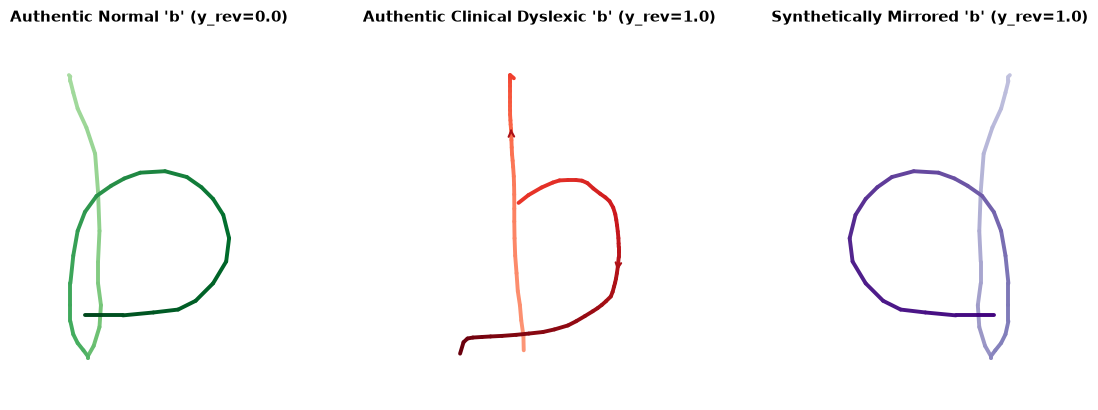

In [48]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def get_sample_bounding_box(strokes: List[List[Tuple[float, float]]]) -> Tuple[float, float, float, float]:
    all_x = [pt[0] for stroke in strokes for pt in stroke]
    all_y = [pt[1] for stroke in strokes for pt in stroke]
    if not all_x or not all_y:
        return 0.0, 1.0, 0.0, 1.0
    return min(all_x), max(all_x), min(all_y), max(all_y)

def plot_strokes_with_trajectory(ax, strokes, title, color_map="Blues"):
    """Plots trajectory with progressive directional color gradients and flow arrows."""
    cmap = plt.get_cmap(color_map)
    min_x, max_x, min_y, max_y = get_sample_bounding_box(strokes)
    total_pts = sum(len(s) for s in strokes)
    pt_counter = 0
    
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        xs = [pt[0] for pt in stroke]
        ys = [pt[1] for pt in stroke]
        
        for i in range(len(stroke) - 1):
            t = (pt_counter + i) / max(total_pts - 1, 1)
            ax.plot(
                [xs[i], xs[i+1]], 
                [ys[i], ys[i+1]], 
                color=cmap(0.35 + 0.65 * t), 
                linewidth=2.8, 
                solid_capstyle='round'
            )
            
            if len(stroke) >= 4 and i == len(stroke) // 2:
                ax.annotate(
                    '', 
                    xy=(xs[i+1], ys[i+1]), 
                    xytext=(xs[i], ys[i]),
                    arrowprops=dict(arrowstyle="->", color=cmap(0.85), lw=1.5)
                )
        pt_counter += len(stroke)
        
    margin_x = max((max_x - min_x) * 0.15, 0.05)
    margin_y = max((max_y - min_y) * 0.15, 0.05)
    ax.set_xlim(min_x - margin_x, max_x + margin_x)
    ax.set_ylim(max_y + margin_y, min_y - margin_y)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    ax.axis('off')

# Find representative samples for visual inspection
sample_norm = next((s for s in local_train_samples if s['label'] == 'b' and not s['is_atypical']), local_train_samples[0])
sample_atyp = next((s for s in local_train_samples if s['label'] == 'b' and s['is_atypical']), local_train_samples[1])

min_x, max_x, _, _ = get_sample_bounding_box(sample_norm['strokes'])
mirrored_strokes = [[(min_x + max_x - pt[0], pt[1]) for pt in stroke] for stroke in sample_norm['strokes']]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
plot_strokes_with_trajectory(axes[0], sample_norm['strokes'], f"Authentic Normal '{sample_norm['label']}' (y_rev=0.0)", "Greens")
plot_strokes_with_trajectory(axes[1], sample_atyp['strokes'], f"Authentic Clinical Dyslexic '{sample_atyp['label']}' (y_rev=1.0)", "Reds")
plot_strokes_with_trajectory(axes[2], mirrored_strokes, f"Synthetically Mirrored '{sample_norm['label']}' (y_rev=1.0)", "Purples")
plt.tight_layout()
plt.show()


### 10.1 Equidistant Arc-Length Resampling & Asymmetric Reversal Dynamics

1. **Equidistant Arc-Length Parameterization ($T=64$):** Standardizes coordinate trajectories while preserving authentic aspect ratios and air-stroke transitions.
2. **8 Kinematic Feature Channels ($F=8$):** $[\Delta x, \Delta y, \cos\\theta, \sin\\theta, \Delta\\theta, d^2x, d^2y, \\text{pen\\_state}]$.
3. **Decoupled Asymmetric Reversal Training:**
   - **Authentic Samples:** Both heads actively learn character identity and reversal state (`sw_char = 1.0, sw_rev = 1.0`).
   - **Asymmetric Letters (`B, C, D, E, F, G, J, K, L, N, P, R, S, Z` and lowercase `c, e, f, g, h, j, k, r, s, z`):**
     Synthetically horizontally mirrored. Head 1 actively learns character identity (`y_char = c_idx`, `sw_char = 1.0` so Head 1 recognizes `ꓭ` is `'B'`, `Ǝ` is `'E'`), and Head 2 learns reversal detection (`y_rev = 1.0`, `sw_rev = 1.0`).
   - **Chiral Homoglyph Pairs ($b \leftrightarrow d$, $p \leftrightarrow q$):**
     Excluded from naive horizontal flipping to eliminate supervisor label contradiction on Head 2. Chiral reversals are captured via authentic tablet atypical samples and target prompt alignment in the Dual-Track Resolver.
4. **Validation Set:** Strictly unaugmented authentic tablet holdout (`dhrc_val_datasets/`).


In [49]:
def resample_and_normalize_sample(
    sample: Dict[str, Any], 
    target_len: int = DHRC_SEQ_LEN
) -> Dict[str, np.ndarray]:
    """Resamples stroke trajectories to fixed length T with arc-length equidistant sampling."""
    strokes = sample.get('strokes', [])
    if not strokes or sum(len(s) for s in strokes) == 0:
        return {
            'x': np.zeros(target_len, dtype=np.float32),
            'y': np.zeros(target_len, dtype=np.float32),
            'pen_state': np.zeros(target_len, dtype=np.float32)
        }

    raw_x, raw_y, raw_pen = [], [], []
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        if s_idx > 0 and len(raw_x) > 0:
            raw_x.append(stroke[0][0])
            raw_y.append(stroke[0][1])
            raw_pen.append(0.0)  # Air-stroke transition
        for pt in stroke:
            raw_x.append(float(pt[0]))
            raw_y.append(float(pt[1]))
            raw_pen.append(1.0)  # On-surface writing

    raw_x = np.array(raw_x, dtype=np.float64)
    raw_y = np.array(raw_y, dtype=np.float64)
    raw_pen = np.array(raw_pen, dtype=np.float64)

    min_x, max_x = np.min(raw_x), np.max(raw_x)
    min_y, max_y = np.min(raw_y), np.max(raw_y)
    scale = max(max_x - min_x, max_y - min_y, 1e-6)

    norm_x = (raw_x - min_x) / scale
    norm_y = (raw_y - min_y) / scale

    dx = np.diff(norm_x)
    dy = np.diff(norm_y)
    step_distances = np.sqrt(dx**2 + dy**2)
    cum_dist = np.empty(len(norm_x), dtype=np.float64)
    cum_dist[0] = 0.0
    cum_dist[1:] = np.cumsum(step_distances)
    total_length = cum_dist[-1]

    if total_length < 1e-6:
        return {
            'x': np.full(target_len, norm_x[0], dtype=np.float32),
            'y': np.full(target_len, norm_y[0], dtype=np.float32),
            'pen_state': np.ones(target_len, dtype=np.float32)
        }

    query_dist = np.linspace(0.0, total_length, target_len)
    res_x = np.interp(query_dist, cum_dist, norm_x).astype(np.float32)
    res_y = np.interp(query_dist, cum_dist, norm_y).astype(np.float32)
    interp_pen = np.interp(query_dist, cum_dist, raw_pen)
    res_pen = (interp_pen >= 0.5).astype(np.float32)

    return {'x': res_x, 'y': res_y, 'pen_state': res_pen}

def extract_reversal_kinematic_features(
    resampled_data: Dict[str, np.ndarray],
    eps: float = 1e-7
) -> np.ndarray:
    """Extracts an 8-dimensional kinematic and geometric trajectory feature matrix."""
    x = resampled_data['x']
    y = resampled_data['y']
    pen_state = resampled_data['pen_state']
    T = len(x)

    dx = np.empty(T, dtype=np.float32)
    dy = np.empty(T, dtype=np.float32)
    dx[0], dy[0] = 0.0, 0.0
    dx[1:] = np.diff(x)
    dy[1:] = np.diff(y)

    ds = np.sqrt(dx**2 + dy**2) + eps
    cos_theta = dx / ds
    sin_theta = dy / ds

    d_theta = np.zeros(T, dtype=np.float32)
    d_theta[1:] = sin_theta[1:] * cos_theta[:-1] - cos_theta[1:] * sin_theta[:-1]

    d2x = np.zeros(T, dtype=np.float32)
    d2y = np.zeros(T, dtype=np.float32)
    d2x[1:] = np.diff(dx)
    d2y[1:] = np.diff(dy)

    return np.column_stack([
        dx, dy, cos_theta, sin_theta, d_theta, d2x, d2y, pen_state.astype(np.float32)
    ])

# -----------------------------------------------------------------------------
# BUILD TRAINING TENSORS WITH ASYMMETRIC REVERSAL DYNAMICS
# -----------------------------------------------------------------------------
X_train_list, y_char_train_list, y_rev_train_list = [], [], []
sw_char_train_list, sw_rev_train_list = [], []

for s in train_samples:
    lbl = s['label']
    c_idx = CHAR_TO_IDX[lbl]
    is_atyp = s['is_atypical']
    
    # 1. Authentic sample (Both heads learn: authentic character identity and reversal state)
    res_auth = resample_and_normalize_sample(s)
    feat_auth = extract_reversal_kinematic_features(res_auth)
    X_train_list.append(feat_auth)
    y_char_train_list.append(c_idx)
    y_rev_train_list.append(1.0 if is_atyp else 0.0)
    sw_char_train_list.append(1.0)
    sw_rev_train_list.append(1.0)
    
    # 2. Augment Asymmetric Letters ONLY (Never flip chiral homoglyphs like b <-> d)
    if not is_atyp:
        if lbl in ASYMMETRIC_REVERSIBLE_CHARS:
            min_x, max_x, _, _ = get_sample_bounding_box(s['strokes'])
            mir_strokes = [[(min_x + max_x - pt[0], pt[1]) for pt in stroke] for stroke in s['strokes']]
            res_mir = resample_and_normalize_sample({'strokes': mir_strokes})
            X_train_list.append(extract_reversal_kinematic_features(res_mir))
            
            # Head 1 actively learns character identity (ꓭ is 'B', Ǝ is 'E', ᗡ is 'D')
            y_char_train_list.append(c_idx)
            sw_char_train_list.append(1.0)
            
            # Head 2 actively learns clinical reversal
            y_rev_train_list.append(1.0)
            sw_rev_train_list.append(1.0)

# -----------------------------------------------------------------------------
# BUILD VALIDATION TENSORS (100% PURE AUTHENTIC LOCAL TABLET HOLDOUT)
# -----------------------------------------------------------------------------
X_val_list, y_char_val_list, y_rev_val_list = [], [], []

for s in val_samples:
    lbl = s['label']
    c_idx = CHAR_TO_IDX[lbl]
    res_val = resample_and_normalize_sample(s)
    X_val_list.append(extract_reversal_kinematic_features(res_val))
    y_char_val_list.append(c_idx)
    y_rev_val_list.append(1.0 if s['is_atypical'] else 0.0)

X_train = np.array(X_train_list, dtype=np.float32)
y_char_train = np.array(y_char_train_list, dtype=np.int32)
y_rev_train = np.array(y_rev_train_list, dtype=np.float32).reshape(-1, 1)
sw_char_train = np.array(sw_char_train_list, dtype=np.float32)
sw_rev_train = np.array(sw_rev_train_list, dtype=np.float32)

X_val = np.array(X_val_list, dtype=np.float32)
y_char_val = np.array(y_char_val_list, dtype=np.int32)
y_rev_val = np.array(y_rev_val_list, dtype=np.float32).reshape(-1, 1)

print("Tensors constructed successfully:")
print(f"  Training Corpus:    X={X_train.shape}, y_char={y_char_train.shape}, y_rev={y_rev_train.shape}")
print(f"    -> Authentic (0.0): {np.sum(y_rev_train == 0.0)} | Reversed/Atypical (1.0): {np.sum(y_rev_train == 1.0)}")
print(f"    -> Head 1 Active Loss: {int(np.sum(sw_char_train))} / {len(sw_char_train)} (100% active supervision)")
print(f"  Validation Holdout: X={X_val.shape}, y_char={y_char_val.shape}, y_rev={y_rev_val.shape}")
print(f"    -> Authentic (0.0): {np.sum(y_rev_train == 0.0)} | Reversed/Atypical (1.0): {np.sum(y_rev_train == 1.0)}")


Tensors constructed successfully:
  Training Corpus:    X=(10277, 64, 8), y_char=(10277,), y_rev=(10277, 1)
    -> Authentic (0.0): 6683 | Reversed/Atypical (1.0): 3594
    -> Head 1 Active Loss: 10277 / 10277 (100% active supervision)
  Validation Holdout: X=(198, 64, 8), y_char=(198,), y_rev=(198, 1)
    -> Authentic (0.0): 6683 | Reversed/Atypical (1.0): 3594


### 10.2 Centralized Architecture Compilation & Dynamic Training

- **Architecture:** Sourced directly from `build_dhrc_model()` in [`scripts/model_builder.py`](file:///Users/asthiseta/Project/somethinginmyeye/scripts/model_builder.py):
  - Shared feature extractor: 2x Conv1D + BatchNorm + MaxPool + Bidirectional GRU (32 units) + GAP + Dense(64, ReLU) + Dropout(0.35).
  - Head 1 (`char_output`): Dense(52, Softmax) predicting canonical Latin character.
  - Head 2 (`reversal_output`): Dense(1, Sigmoid) predicting clinical reversal risk.
- **Dynamic Training Strategy:** Ceiling 50 epochs with `EarlyStopping(monitor='val_reversal_output_auc', mode='max', patience=10, restore_best_weights=True)` and `ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)`.


In [64]:
import os
os.environ['KERAS_HOME'] = '/tmp/keras'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from model_builder import build_dhrc_model
from config import (
    DHRC_SEQ_LEN,
    DHRC_FEATURES,
    DHRC_NUM_CLASSES,
    DHRC_EPOCHS,
    DHRC_BATCH_SIZE,
    DHRC_PATIENCE,
    DHRC_REDUCE_LR_PATIENCE,
    DHRC_MODEL_PATH
)

print("Instantiating DHRC model from centralized model_builder...")
reversal_model = build_dhrc_model(
    seq_len=DHRC_SEQ_LEN,
    num_features=DHRC_FEATURES,
    num_classes=DHRC_NUM_CLASSES
)

callbacks = [
    EarlyStopping(
        monitor='val_reversal_output_auc',
        mode='max',
        patience=DHRC_PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=DHRC_REDUCE_LR_PATIENCE,
        min_lr=1e-5,
        verbose=1
    )
]

print(f"Beginning dynamic training (Ceiling: {DHRC_EPOCHS} epochs, Batch Size: {DHRC_BATCH_SIZE})...")
history = reversal_model.fit(
    X_train,
    (y_char_train, y_rev_train),
    sample_weight=(sw_char_train, sw_rev_train),
    validation_data=(X_val, (y_char_val, y_rev_val)),
    epochs=DHRC_EPOCHS,
    batch_size=DHRC_BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

# Plot Training Dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Character Head Metrics
char_acc_key = next((k for k in history.history if 'char_output' in k and 'acc' in k), 'char_output_accuracy')
val_char_acc_key = f'val_{char_acc_key}'

axes[0].plot(history.history[char_acc_key], label='Train Accuracy', lw=2)
if val_char_acc_key in history.history:
    axes[0].plot(history.history[val_char_acc_key], label='Val Accuracy', lw=2, linestyle='--')
axes[0].set_title('Head 1: Character Classification Accuracy (52 Classes)', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Reversal Head Metrics
rev_auc_key = next((k for k in history.history if 'reversal_output' in k and 'auc' in k), 'reversal_output_auc')
val_rev_auc_key = f'val_{rev_auc_key}'

axes[1].plot(history.history[rev_auc_key], label='Train ROC-AUC', lw=2, color='crimson')
if val_rev_auc_key in history.history:
    axes[1].plot(history.history[val_rev_auc_key], label='Val ROC-AUC', lw=2, linestyle='--', color='darkorange')
axes[1].set_title('Head 2: Clinical Reversal Detection ROC-AUC', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Instantiating DHRC model from centralized model_builder...
Beginning dynamic training (Ceiling: 50 epochs, Batch Size: 32)...
Epoch 1/50
322/322 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - char_output_accuracy: 0.1854 - char_output_loss: 3.0454 - loss: 3.5414 - reversal_output_accuracy: 0.8682 - reversal_output_auc: 0.9212 - reversal_output_loss: 0.3304 - val_char_output_accuracy: 0.1061 - val_char_output_loss: 3.2642 - val_loss: 4.1821 - val_reversal_output_accuracy: 0.5960 - val_reversal_output_auc: 0.5567 - val_reversal_output_loss: 0.6979 - learning_rate: 0.0010
Epoch 2/50
322/322 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - char_output_accuracy: 0.4172 - char_output_loss: 1.9640 - loss: 2.3212 - reversal_output_accuracy: 0.9212 - reversal_output_auc: 0.9517 - reversal_output_loss: 0.2397 - val_char_output_accuracy: 0.4596 - val_char_output_loss: 1.8707 - val_loss: 2.9215 - val_reversal_output_accuracy: 0.7222 - val_reversal_output_auc: 0.7563 - val_reversal_output_loss: 0.6050 - learning_rate: 0.001

KeyboardInterrupt: 

In [52]:
import tf2onnx
import onnx
import onnxruntime as ort
from config import DHRC_ONNX_PATH, DHRC_MODEL_PATH

# 1. Save Keras Model
os.makedirs(os.path.dirname(DHRC_MODEL_PATH), exist_ok=True)
reversal_model.save(DHRC_MODEL_PATH)
print(f"Trained Keras model saved to: {DHRC_MODEL_PATH}")

# Backup in scratch/
os.makedirs("scratch", exist_ok=True)
reversal_model.save("scratch/dual_head_reversal_model.keras")

# 2. Export to ONNX for Web Runtime
input_signature = [
    tf.TensorSpec(shape=(None, DHRC_SEQ_LEN, DHRC_FEATURES), dtype=tf.float32, name="trajectory_input")
]

os.makedirs(os.path.dirname(DHRC_ONNX_PATH), exist_ok=True)
onnx_model, _ = tf2onnx.convert.from_keras(
    reversal_model,
    input_signature=input_signature,
    opset=15,
    output_path=DHRC_ONNX_PATH
)

onnx_size_kb = os.path.getsize(DHRC_ONNX_PATH) / 1024.0
print(f"Exported ONNX model to: {DHRC_ONNX_PATH} ({onnx_size_kb:.2f} KB)")

# 3. Numerical Parity Verification
ort_session = ort.InferenceSession(DHRC_ONNX_PATH)
test_input = np.random.randn(4, DHRC_SEQ_LEN, DHRC_FEATURES).astype(np.float32)

keras_preds = reversal_model.predict(test_input, verbose=0)
input_name = ort_session.get_inputs()[0].name
ort_preds = ort_session.run(None, {input_name: test_input})

if ort_preds[0].shape[-1] == DHRC_NUM_CLASSES:
    ort_char, ort_rev = ort_preds[0], ort_preds[1]
else:
    ort_rev, ort_char = ort_preds[0], ort_preds[1]

diff_char = np.max(np.abs(keras_preds[0] - ort_char))
diff_rev = np.max(np.abs(keras_preds[1] - ort_rev))
print(f"ONNX Parity Difference: Character Max Diff = {diff_char:.2e}, Reversal Max Diff = {diff_rev:.2e}")
assert diff_char < 1e-4 and diff_rev < 1e-4, "ONNX numerical parity check failed!"
print("ONNX numerical parity verified successfully.")


Trained Keras model saved to: /Users/asthiseta/Project/somethinginmyeye/models/dual_head_reversal_model.keras
Exported ONNX model to: /Users/asthiseta/Project/somethinginmyeye/data_collector/models/dual_head_reversal.onnx (176.59 KB)
ONNX Parity Difference: Character Max Diff = 1.79e-07, Reversal Max Diff = 1.79e-07
ONNX numerical parity verified successfully.


### 10.3 Quantitative Evaluation & Reversal Detection Metrics

Evaluates Head 1 (52-class Top-1, case-insensitive Top-1, and Top-3 accuracy) and Head 2 (reversal discriminability) on the pure held-out tablet cohort (`dhrc_val_datasets/`).


Evaluating Dual-Head Model on Pure Validation Holdout (dhrc_val_datasets/)...
             DUAL-HEAD REVERSAL CLASSIFIER EVALUATION             
Head 1 (Character Softmax - 52 Classes):
  -> Exact Top-1 Accuracy:            67.17%
  -> Case-Insensitive Top-1 Accuracy: 83.84%
  -> Top-3 Accuracy:                  86.36%
----------------------------------------------------------------------
Head 2 (Clinical Reversal Detection):
  -> ROC-AUC Score:  0.7872
  -> Confusion Matrix:
[[124   6]
 [ 46  22]]
----------------------------------------------------------------------
Reversal Classification Report:
               precision    recall  f1-score   support

Authentic (0)       0.73      0.95      0.83       130
 Reversed (1)       0.79      0.32      0.46        68

     accuracy                           0.74       198
    macro avg       0.76      0.64      0.64       198
 weighted avg       0.75      0.74      0.70       198



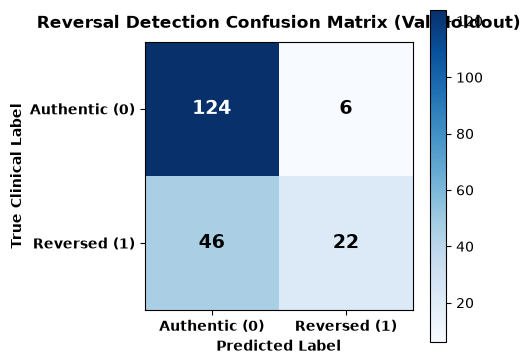

In [53]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Evaluating Dual-Head Model on Pure Validation Holdout (dhrc_val_datasets/)...")
val_preds = reversal_model.predict(X_val, verbose=0)
char_probs = val_preds[0]
rev_probs = val_preds[1].ravel()

# Head 1: Character Classification
char_preds_top1 = np.argmax(char_probs, axis=1)
top1_acc = np.mean(char_preds_top1 == y_char_val) * 100.0

# Case-Insensitive Top-1 Accuracy (accounts for geometric homoglyphs c/C, o/O, s/S, etc.)
case_insensitive_correct = 0
for i in range(len(y_char_val)):
    pred_char = VOCABULARY[char_preds_top1[i]]
    true_char = VOCABULARY[y_char_val[i]]
    if pred_char.lower() == true_char.lower():
        case_insensitive_correct += 1
case_insensitive_acc = (case_insensitive_correct / len(y_char_val)) * 100.0

# Top-3 Accuracy
top3_correct = 0
for i in range(len(y_char_val)):
    top3_idx = np.argsort(char_probs[i])[-3:]
    if y_char_val[i] in top3_idx:
        top3_correct += 1
top3_acc = (top3_correct / len(y_char_val)) * 100.0

# Head 2: Reversal Detection
rev_preds = (rev_probs >= 0.50).astype(int)
rev_auc = roc_auc_score(y_rev_val, rev_probs)
cm = confusion_matrix(y_rev_val, rev_preds)

print("=" * 70)
print("             DUAL-HEAD REVERSAL CLASSIFIER EVALUATION             ")
print("=" * 70)
print(f"Head 1 (Character Softmax - 52 Classes):")
print(f"  -> Exact Top-1 Accuracy:            {top1_acc:.2f}%")
print(f"  -> Case-Insensitive Top-1 Accuracy: {case_insensitive_acc:.2f}%")
print(f"  -> Top-3 Accuracy:                  {top3_acc:.2f}%")
print("-" * 70)
print(f"Head 2 (Clinical Reversal Detection):")
print(f"  -> ROC-AUC Score:  {rev_auc:.4f}")
print(f"  -> Confusion Matrix:\n{cm}")
print("-" * 70)
print("Reversal Classification Report:")
print(classification_report(y_rev_val, rev_preds, target_names=['Authentic (0)', 'Reversed (1)']))
print("=" * 70)

# Visual Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
plt.colorbar(im, ax=ax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Authentic (0)', 'Reversed (1)'], fontsize=10, fontweight='bold')
ax.set_yticklabels(['Authentic (0)', 'Reversed (1)'], fontsize=10, fontweight='bold')
ax.set_xlabel('Predicted Label', fontweight='bold')
ax.set_ylabel('True Clinical Label', fontweight='bold')
ax.set_title('Reversal Detection Confusion Matrix (Val Holdout)', fontweight='bold', pad=10)

for i in range(2):
    for j in range(2):
        text_color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=text_color, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### 10.4 Interactive Stroke Tester & Single-Sample Verification

Inspects individual tablet recordings or live strokes through the trained dual-head model.


Running Verification Suite...
Testing Normal 'B':


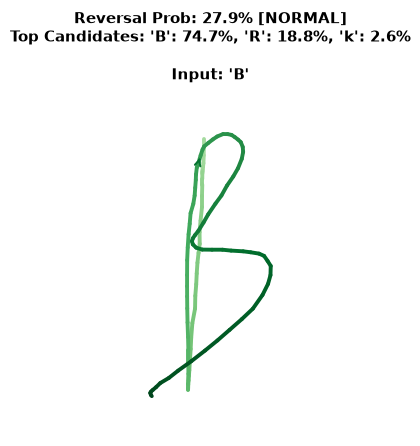

Testing Mirrored 'B' (ꓭ):


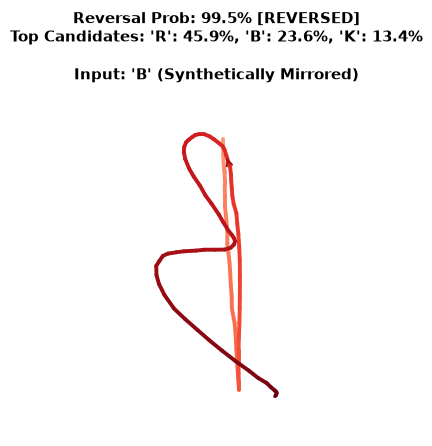

Testing Authentic Normal 'd':


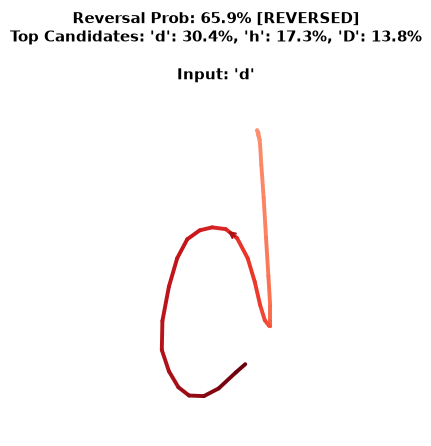

Testing Authentic Normal 'b':


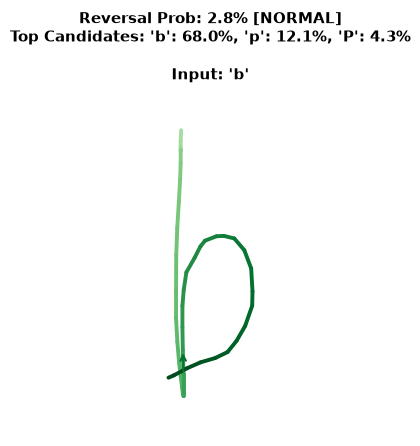

In [54]:
def test_sample_inference(
    sample: Dict[str, Any], 
    model_instance=reversal_model,
    flip_horizontal: bool = False
):
    """Evaluates a single sample and plots its trajectory with dual-head prediction results."""
    strokes = sample['strokes']
    lbl = sample.get('label', '?')
    
    if flip_horizontal:
        min_x, max_x, _, _ = get_sample_bounding_box(strokes)
        strokes = [[(min_x + max_x - pt[0], pt[1]) for pt in stroke] for stroke in strokes]
        display_label = f"'{lbl}' (Synthetically Mirrored)"
    else:
        display_label = f"'{lbl}'"

    eval_sample = dict(sample)
    eval_sample['strokes'] = strokes
    res = resample_and_normalize_sample(eval_sample)
    feats = extract_reversal_kinematic_features(res)
    inp = np.expand_dims(feats, axis=0)
    
    preds = model_instance.predict(inp, verbose=0)
    char_probs = preds[0][0]
    rev_prob = float(preds[1][0][0])
    
    top3_idx = np.argsort(char_probs)[-3:][::-1]
    top3_results = [(VOCABULARY[idx], float(char_probs[idx])) for idx in top3_idx]
    
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    color_map = "Reds" if rev_prob >= 0.50 else "Greens"
    plot_strokes_with_trajectory(ax, strokes, f"Input: {display_label}", color_map)
    
    rev_tag = "[REVERSED]" if rev_prob >= 0.50 else "[NORMAL]"
    candidates_str = ", ".join([f"'{c}': {p*100:.1f}%" for c, p in top3_results])
    
    top_pred = top3_results[0][0]
    chiral_note = ""
    if (lbl, top_pred) in [('b', 'd'), ('d', 'b'), ('p', 'q'), ('q', 'p')]:
        chiral_note = f"\n[CHIRAL SUBSTITUTION]: Prompt '{lbl}' -> Predicted '{top_pred}'"
        
    plt.suptitle(
        f"Reversal Prob: {rev_prob*100:.1f}% {rev_tag}\nTop Candidates: {candidates_str}{chiral_note}",
        fontsize=11,
        fontweight='bold',
        y=0.98
    )
    plt.tight_layout()
    plt.show()

# Verification Suite
print("Running Verification Suite...")

# 1. Test authentic normal 'B' vs mirrored 'B' (ꓭ)
sample_B = next((s for s in val_samples if s['label'] == 'B'), val_samples[0])
print("Testing Normal 'B':")
test_sample_inference(sample_B, flip_horizontal=False)
print("Testing Mirrored 'B' (ꓭ):")
test_sample_inference(sample_B, flip_horizontal=True)

# 2. Test authentic normal 'd' vs normal 'b'
sample_d = next((s for s in val_samples if s['label'] == 'd'), val_samples[1])
print("Testing Authentic Normal 'd':")
test_sample_inference(sample_d, flip_horizontal=False)

sample_b = next((s for s in val_samples if s['label'] == 'b'), val_samples[2])
print("Testing Authentic Normal 'b':")
test_sample_inference(sample_b, flip_horizontal=False)


## 11. Interactive Sandbox / Scratchpad
Dedicated scratchpad area for free-form experimentation.


In [ ]:
# Free scratchpad space for rapid interactive testing
